### Import Libraries

In [29]:
import os, random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [30]:
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

### Functions

In [31]:
def build_baseline():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name="cnn_flatliner_baseline")
    return model

In [ ]:
def build_altered():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name="cnn_flatliner_altered")
    return model

In [33]:
def plot_curves(histories, labels, metric="val_accuracy"):
    plt.figure(figsize=(12, 6))
    for history, label in zip(histories, labels):
        plt.plot(history.history[metric], label=f"{label} {metric}")
    plt.title(f"Training and Validation {metric}")
    plt.xlabel("Epochs")
    plt.ylabel(metric)
    plt.legend()
    plt.grid()
    plt.show()

### Obtain Data

In [34]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()  

In [35]:
print("Training data shape:", x_train.shape, y_train.shape)
print("Testing data shape:", x_test.shape, y_test.shape)

Training data shape: (60000, 28, 28) (60000,)
Testing data shape: (10000, 28, 28) (10000,)


In [36]:
x_train = (x_train.astype(np.float32) / 255.0)[..., np.newaxis]
x_test = (x_test.astype(np.float32) / 255.0)[..., np.newaxis]

In [37]:
print("New shape of training data:", x_train.shape)
print("New shape of test data:", x_test.shape)

New shape of training data: (60000, 28, 28, 1)
New shape of test data: (10000, 28, 28, 1)


### Modelling

In [38]:
baseline = build_baseline()
baseline.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
baseline.summary()

Model: "cnn_flatliner_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history_baseline = baseline.fit(x_train, y_train, batch_size=128, epochs=3, validation_split=0.1, verbose=2)

Epoch 1/3
422/422 - 10s - 24ms/step - accuracy: 0.9404 - loss: 0.2049 - val_accuracy: 0.9838 - val_loss: 0.0613
Epoch 2/3
422/422 - 7s - 18ms/step - accuracy: 0.9833 - loss: 0.0544 - val_accuracy: 0.9875 - val_loss: 0.0478
Epoch 3/3
422/422 - 7s - 17ms/step - accuracy: 0.9888 - loss: 0.0361 - val_accuracy: 0.9898 - val_loss: 0.0378


In [40]:
test_loss, test_accuracy = baseline.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.0319
Test accuracy: 0.9895


In [41]:
cnn_custom = build_altered()
cnn_custom.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
cnn_custom.summary()

Model: "cnn_flatliner_altered"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,026 (148.54 KB)

 Trainable params: 38,026 (148.54 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
history_custom = cnn_custom.fit(x_train, y_train, batch_size=128, epochs=3, validation_split=0.1, verbose=2)

Epoch 1/3
422/422 - 7s - 17ms/step - accuracy: 0.3693 - loss: 1.6676 - val_accuracy: 0.5218 - val_loss: 1.3297
Epoch 2/3
422/422 - 7s - 16ms/step - accuracy: 0.5980 - loss: 1.1719 - val_accuracy: 0.7230 - val_loss: 0.8850
Epoch 3/3
422/422 - 7s - 16ms/step - accuracy: 0.7302 - loss: 0.8128 - val_accuracy: 0.7978 - val_loss: 0.6425


In [43]:
test_loss, test_accuracy = cnn_custom.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.6535
Test accuracy: 0.7970


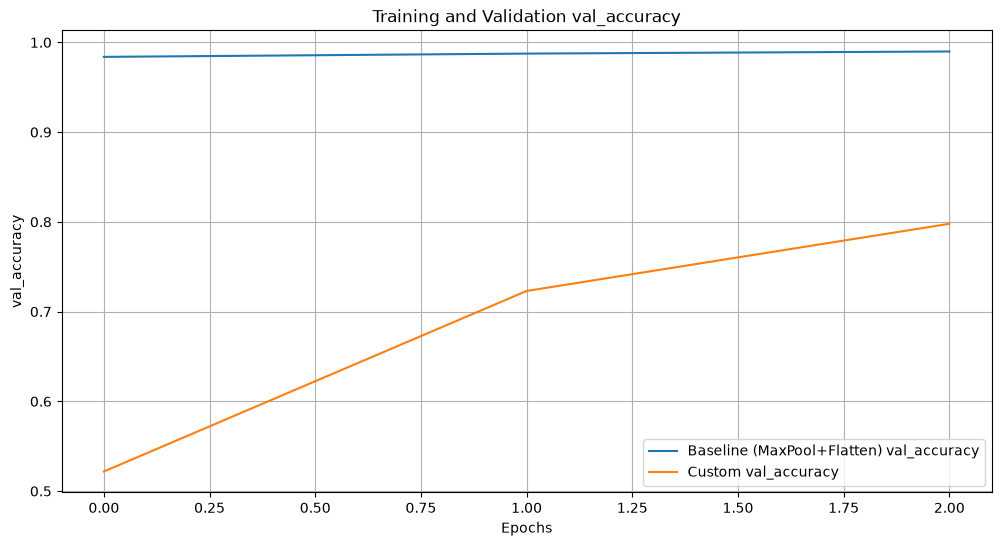

In [44]:
plot_curves([history_baseline, history_custom], ["Baseline (MaxPool+Flatten)", "Custom"], metric="val_accuracy")